# Example 15: Knot unsupervised

In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from xkan import KANNetwork, fit
from xkan.symbolic import fix_symbolic
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

seed = 2024
torch.manual_seed(seed)
np.random.seed(seed)

dtype = torch.get_default_dtype()

# Download data: https://colab.research.google.com/github/deepmind/mathematics_conjectures/blob/main/knot_theory.ipynb#scrollTo=l10N2ZbHu6Ob
# (that notebook's gs://maths_conjectures/knot_theory/knot_theory_invariants.csv, saved here as knot_data.csv)
df = pd.read_csv("./knot_data.csv")
df.keys()

X = df[df.keys()[1:]].to_numpy()
mean = np.mean(X, axis=0)
std = np.std(X, axis=0)
X = (X - mean[np.newaxis,:])/std[np.newaxis,:]

# normalize X
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X = (X - X_mean[np.newaxis,:])/X_std[np.newaxis,:]
input_normalier = [X_mean, X_std]

num = X.shape[0]
n_feature = X.shape[1]
train_ratio = 0.8
train_id_ = np.random.choice(num, int(num*train_ratio), replace=False)
test_id_ = np.array(list(set(range(num))-set(train_id_)))
train_input = torch.from_numpy(X[train_id_]).type(dtype)
test_input = torch.from_numpy(X[test_id_]).type(dtype)

def construct_contrastive_dataset(tensor):
    y = copy.deepcopy(tensor)
    for i in range(y.shape[1]):
        y[:,i] = y[:,i][torch.randperm(y.shape[0])]
    return y

contrastive_train_input = construct_contrastive_dataset(train_input)
contrastive_test_input = construct_contrastive_dataset(test_input)

# inputs under 'x' (the knots, then the corrupted samples), labels under 'y' (1 for a knot, 0 for a corrupted sample)
train = {'x': torch.cat([train_input, contrastive_train_input], dim=0).to(device),
         'y': torch.cat([torch.ones(train_input.shape[0],1), torch.zeros(contrastive_train_input.shape[0],1)], dim=0).to(device)}
test = {'x': torch.cat([test_input, contrastive_test_input], dim=0).to(device),
        'y': torch.cat([torch.ones(test_input.shape[0],1), torch.zeros(contrastive_test_input.shape[0],1)], dim=0).to(device)}

cuda


In [2]:
def train_acc():
    return torch.mean(((model(train['x']) > 0.5) == train['y']).float())

def test_acc():
    return torch.mean(((model(test['x']) > 0.5) == test['y']).float())

model = KANNetwork([n_feature, 1, 1], grid=5, k=3, seed=seed, device=device)
fix_symbolic(model, 1, 0, 0, 'gaussian', fit=False)
history = fit(model, train, test, lamb=0.001, batch=1024)
print('train_loss', history['train/y'][-1] ** 0.5, '| reg', history['train/reg/kan'][-1],
      '| train_acc', train_acc().item(), '| test_acc', test_acc().item())

train_loss 0.13989075398212827 | reg 0.010581834241747856 | train_acc 0.9721276760101318 | test_acc 0.9729640483856201


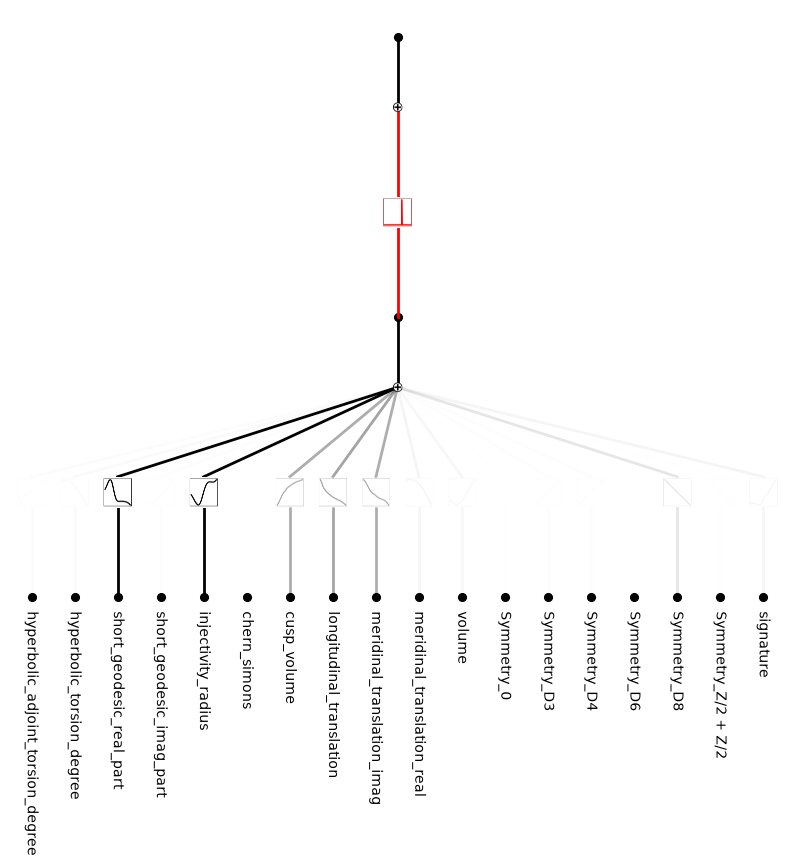

In [3]:
# seed = 2024
plot(model, train['x'], scale=1.0)

n = 18
for i in range(n):
    plt.gcf().get_axes()[0].text(1/(2*n)+i/n-0.005,-0.02,df.keys()[1:][i], rotation=270, rotation_mode="anchor")

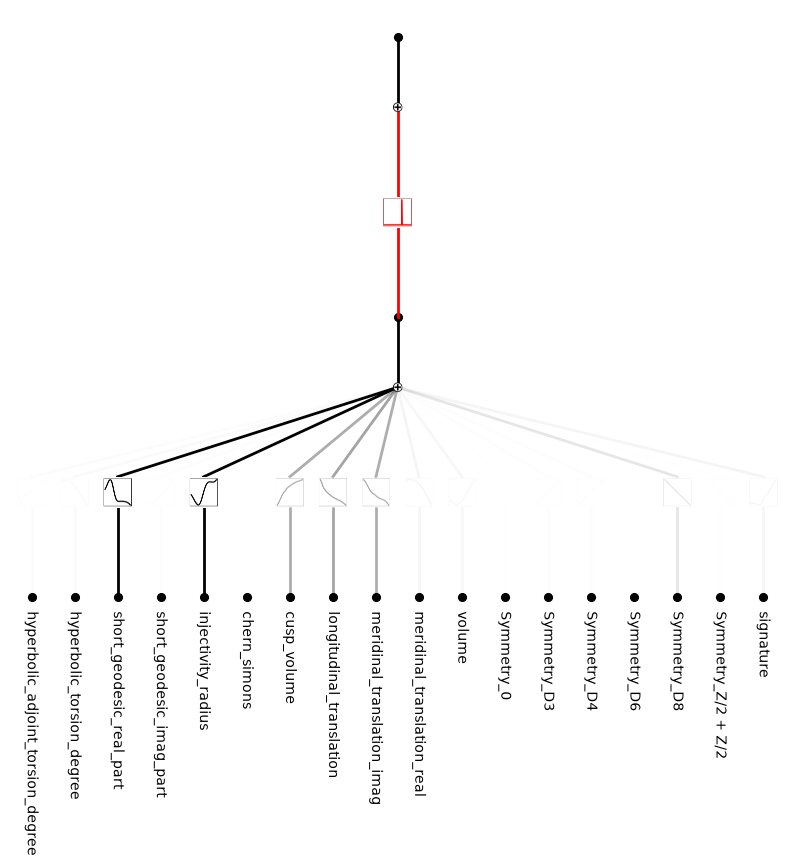

In [4]:
# seed = 0
plot(model, train['x'], scale=1.0)

n = 18
for i in range(n):
    plt.gcf().get_axes()[0].text(1/(2*n)+i/n-0.005,-0.02,df.keys()[1:][i], rotation=270, rotation_mode="anchor")